# Accuracy

In this notebook, we compare the multipole expansion of various orders with exact results.

We use gaussian charge distributions,

$$
\rho(\mathbf{r}) = \sum_i Q_i \frac{\exp\left(-|\mathbf{r}-\mathbf{R}_i|^2 / \sigma^2\right)}{\pi^{3/2}\sigma^3},
$$

whose potential is known exactly:

$$
\Phi(\mathbf{r}) = \sum_i Q_i \frac{\mathrm{erf}\left(|\mathbf{r}-\mathbf{R}_i|/\sigma\right)}{|\mathbf{r}-\mathbf{R}_i|}.
$$

Set up a grid containing the charge distribution, and functions for the charge density and the exact potential:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

from multipoles import MultipoleExpansion

x = y = z = np.linspace(-10, 10, 101)
X, Y, Z = np.meshgrid(x, y, z, indexing="ij")
sigma = 1.5


def charge_density(charges, positions):
    rho = np.zeros_like(X)
    for Q, (x0, y0, z0) in zip(charges, positions):
        R2 = (X - x0)**2 + (Y - y0)**2 + (Z - z0)**2
        rho += Q * np.exp(-R2 / sigma**2) / (np.pi**1.5 * sigma**3)
    return rho


def exact_potential(x, y, z, charges, positions):
    phi = 0
    for Q, (x0, y0, z0) in zip(charges, positions):
        r = np.sqrt((x - x0)**2 + (y - y0)**2 + (z - z0)**2)
        phi += Q * erf(r / sigma) / r
    return phi


def points_along_x(mpe):
    """Distances r from the expansion center where the expansion is valid, and the points
    at these distances in x-direction."""
    r = np.logspace(np.log10(1.01 * mpe.validity_radius), 2, 50)
    x0, y0, z0 = mpe.center
    return r, (x0 + r, y0, z0)


def plot_errors(mpe, charges, positions, l_maxs):
    """Plot the error in x-direction from the expansion center, where the expansion is valid."""
    r, xyz = points_along_x(mpe)
    exact = exact_potential(*xyz, charges, positions)
    for l_max in l_maxs:
        error = np.abs(mpe(*xyz, l_max=l_max) - exact)
        plt.loglog(r, error, "-o", markersize=3, label=f"l_max={l_max}")
    plt.axvline(mpe.validity_radius, color="gray", linestyle="--", label="validity radius")
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.xlabel("distance from the expansion center")
    plt.ylabel("error of the expansion up to l_max")
    plt.grid()
    plt.show()

## A single gaussian at the origin

For a radially symmetric charge distribution, the monopole term is already the exact solution outside the
charge distribution:

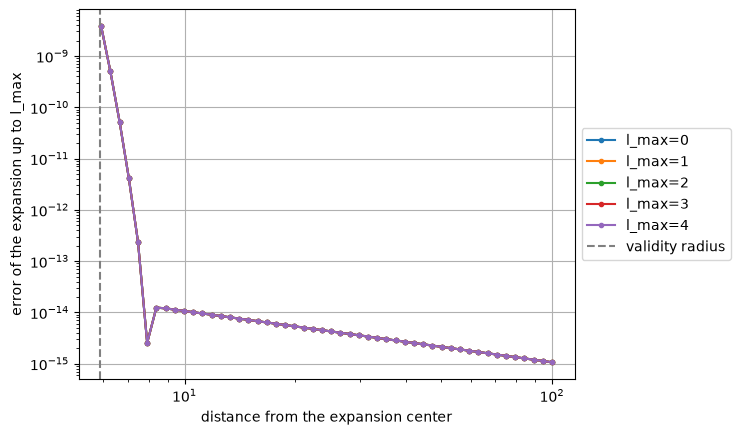

In [2]:
charges, positions = [1], [(0, 0, 0)]
mpe = MultipoleExpansion({"discrete": False, "rho": charge_density(charges, positions), "xyz": (X, Y, Z)}, l_max=8)

plot_errors(mpe, charges, positions, range(5))

All curves are on top of each other at the level of the numerical integration error, so the monopole
is sufficient.

## A shifted gaussian

Shifting the charge distribution away from the origin doesn't change this, because the expansion is done about
the center of charge:

center of charge: [1. 0. 0.]


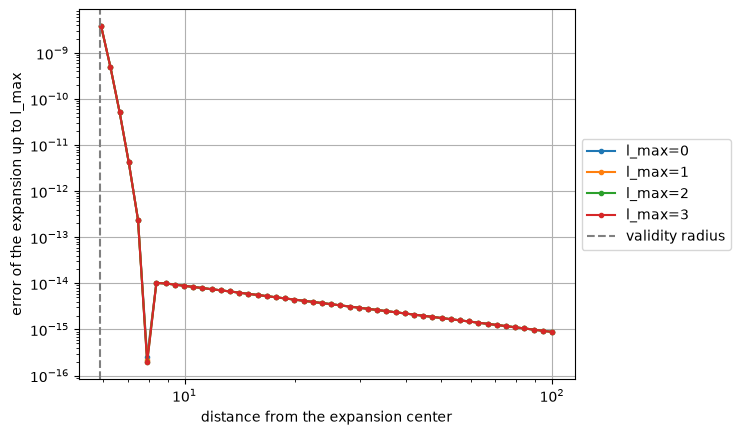

In [3]:
charges, positions = [1], [(1, 0, 0)]
mpe = MultipoleExpansion({"discrete": False, "rho": charge_density(charges, positions), "xyz": (X, Y, Z)}, l_max=8)
print("center of charge:", mpe.center.round(6) + 0.0)  # + 0.0 turns -0.0 into 0.0

plot_errors(mpe, charges, positions, range(4))

If we expand about the origin instead, the charge distribution is no longer symmetric about the expansion
center, and we need the higher multipoles:

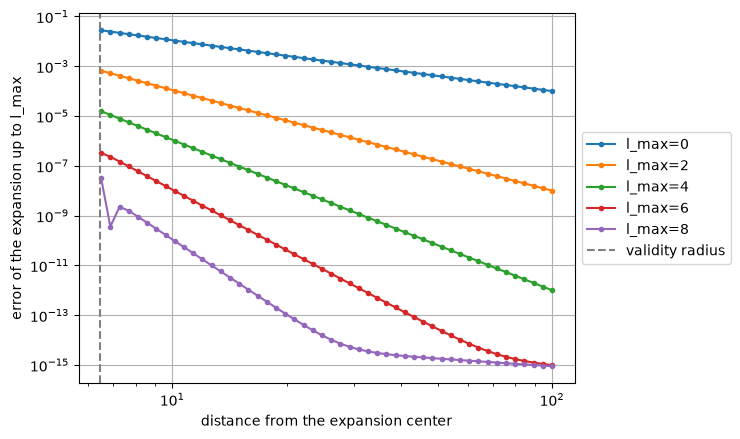

In [4]:
mpe = MultipoleExpansion(
    {"discrete": False, "rho": charge_density(charges, positions), "xyz": (X, Y, Z)}, l_max=8, center=(0, 0, 0)
)

plot_errors(mpe, charges, positions, range(0, 9, 2))

## Several gaussians

With several gaussian charges, many multipole moments are non-zero:

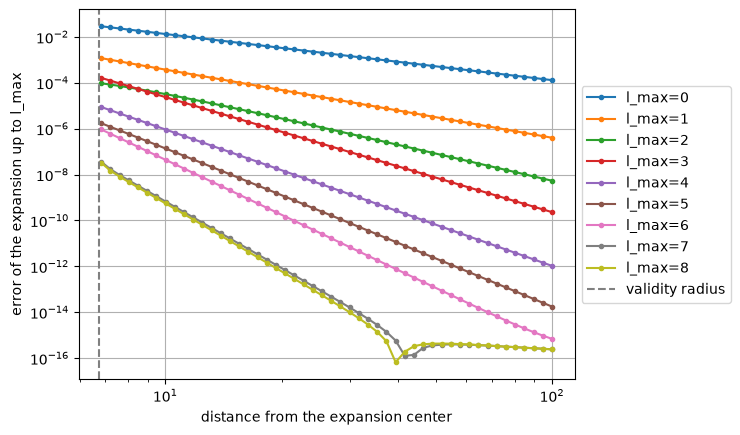

In [5]:
charges = [1, -0.5, -1.5, 0.75]
positions = [(0, 0, 0), (1, 0, 0), (0, 1, 0), (-1, -1, -0.5)]
mpe = MultipoleExpansion({"discrete": False, "rho": charge_density(charges, positions), "xyz": (X, Y, Z)}, l_max=8)

plot_errors(mpe, charges, positions, range(9))

As expected, the more moments we take into account, the smaller the error. The error decreases
geometrically with `l_max`, and the faster, the farther away we are (see [Accuracy](theory.md#accuracy) in
the theory). For this charge distribution, expanding up to the octupole (`l_max=3`) should be sufficient for
most applications.

## The field

The field $\mathbf{E} = -\nabla\Phi$ is equally accurate. We compare it with the numerical derivative of the
exact potential:

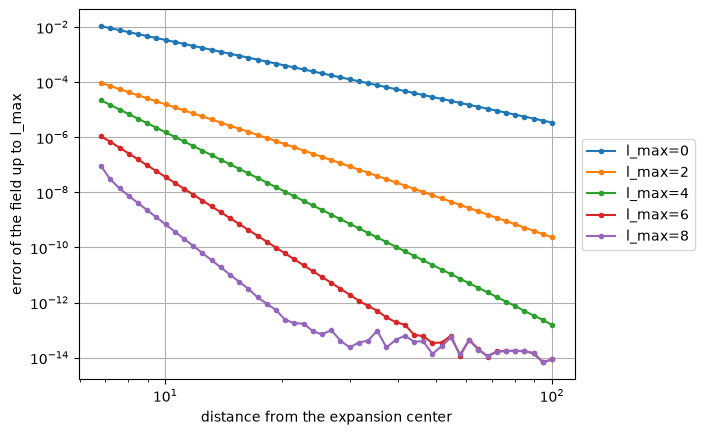

In [6]:
r, (x, y, z) = points_along_x(mpe)
h = 1e-4
E_exact = np.array([
    -(exact_potential(x + h * e[0], y + h * e[1], z + h * e[2], charges, positions)
      - exact_potential(x - h * e[0], y - h * e[1], z - h * e[2], charges, positions)) / (2 * h)
    for e in np.eye(3)
])
for l_max in range(0, 9, 2):
    error = np.linalg.norm(mpe.field(x, y, z, l_max=l_max) - E_exact, axis=0)
    plt.loglog(r, error, "-o", markersize=3, label=f"l_max={l_max}")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.xlabel("distance from the expansion center")
plt.ylabel("error of the field up to l_max")
plt.grid()
plt.show()